# Import bibliotek

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
%matplotlib inline

In [6]:
# !git clone https://github.com/matzim95/ML-datasets

In [7]:
# restart kernel after that
# !pip install -U scikit-learn

ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^


In [2]:
import sklearn
sklearn.__version__

'1.5.1'

# Regresja liniowa

### Jedna zmienna niezależna

In [3]:
df = pd.read_csv("ML-datasets/portland_housing.csv")

In [4]:
df.head()

,Size,Bedrooms,Price
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900


In [5]:
X = df[["Size"]]
y = df["Price"]

In [13]:
# X.iloc[1] = np.nan

In [6]:
display(X[:5])
print(type(X))

,Size
0,2104
1,1600
2,2400
3,1416
4,3000


<class 'pandas.core.frame.DataFrame'>


In [7]:
display(y[:5])
print(type(y))

0    399900
1    329900
2    369000
3    232000
4    539900
Name: Price, dtype: int64

<class 'pandas.core.series.Series'>


In [8]:
from sklearn.linear_model import LinearRegression

In [9]:
# definicja modelu
model_1 = LinearRegression()

In [12]:
# trenowanie modelu
model_1.fit(X, y)

LinearRegression()

In [13]:
model_1.get_params()

{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False}

In [14]:
model_1.coef_ # sigma_1

array([134.52528772])

In [15]:
model_1.intercept_ # sigma_0

71270.49244872911

In [16]:
# price = sigma_0 + sigma_1 * size
# price = 71270 + 134 * size

In [17]:
predict_data = np.array([[3200], [3720]])
predict_data

array([[3200],
       [3720]])

In [18]:
model_1.predict(predict_data)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([501751.4131535 , 571704.56276803])

In [19]:
x_reg = np.linspace(0, 4500, 100)
y_reg = model_1.predict(x_reg.reshape(100,1))

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


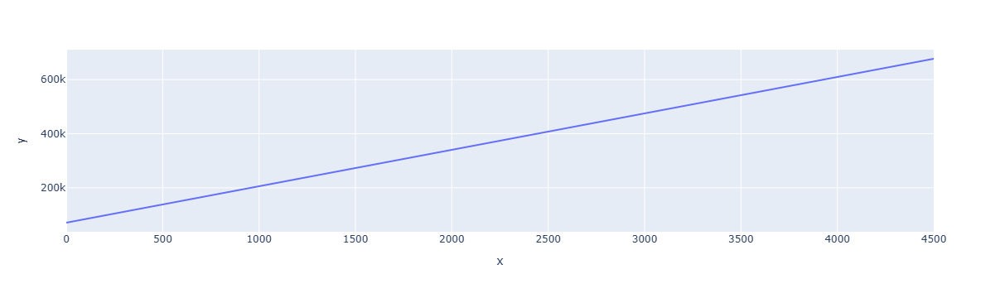

In [20]:
px.line(x=x_reg, y=y_reg)

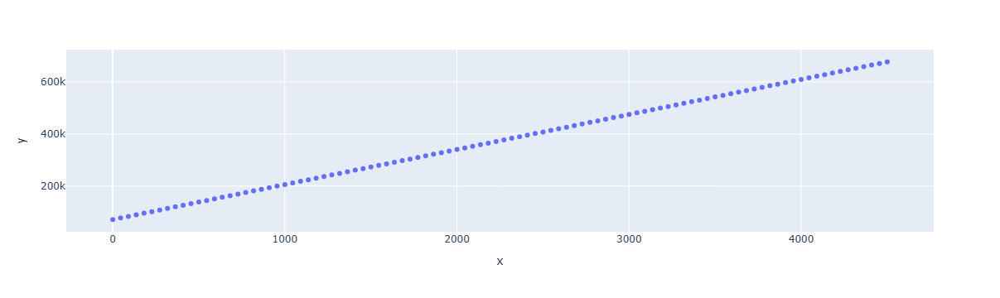

In [22]:
px.scatter(x=x_reg, y=y_reg)

## Regresja liniowa wielu zmiennych

In [23]:
X = df[["Size", "Bedrooms"]]
y = df["Price"]

In [24]:
X[:5]

,Size,Bedrooms
0,2104,3
1,1600,3
2,2400,3
3,1416,2
4,3000,4


In [25]:
model_2 = LinearRegression()
model_2.fit(X, y)

LinearRegression()

In [26]:
model_2.coef_

array([  139.21067402, -8738.01911233])

In [28]:
model_2.intercept_

89597.90954279748

In [29]:
predict_data_2 = np.array([[3200, 3], [3720, 2]])
model_2.predict(predict_data_2)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning:

X does not have valid feature names, but LinearRegression was fitted with feature names



array([508858.00906222, 589985.57866371])

## Regresja wielomianiowa

In [30]:
from sklearn.preprocessing import PolynomialFeatures

In [31]:
X = df[["Size"]]
y = df["Price"]

In [32]:
poly = PolynomialFeatures(degree=3, include_bias=False)

In [35]:
X_poly = poly.fit_transform(X)

In [36]:
X[:5]

,Size
0,2104
1,1600
2,2400
3,1416
4,3000


In [37]:
X_poly[:5]

array([[2.10400000e+03, 4.42681600e+06, 9.31402086e+09],
       [1.60000000e+03, 2.56000000e+06, 4.09600000e+09],
       [2.40000000e+03, 5.76000000e+06, 1.38240000e+10],
       [1.41600000e+03, 2.00505600e+06, 2.83915930e+09],
       [3.00000000e+03, 9.00000000e+06, 2.70000000e+10]])

In [38]:
model_poly = LinearRegression()
model_poly.fit(X_poly, y)

LinearRegression()

In [39]:
model_poly.coef_

array([-1.07855433e+02,  1.06190390e-01, -1.38299982e-05])

In [40]:
model_poly.intercept_

236407.03597276966

In [41]:
predict_data

array([[3200],
       [3720]])

In [43]:
predict_data_poly = poly.fit_transform(predict_data)

In [44]:
model_poly.predict(predict_data_poly)

array([525477.86312142, 592737.54273017])

In [45]:
x_reg = np.linspace(0, 4500, 100)
x_reg_poly = poly.fit_transform(x_reg.reshape(100,1))
y_reg = model_poly.predict(x_reg_poly)

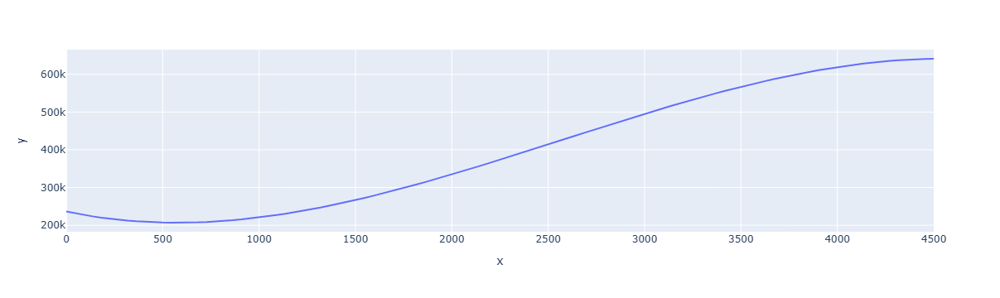

In [46]:
px.line(x=x_reg, y=y_reg)

In [47]:
model_1.score(X, y)

0.7310037839755306

In [48]:
model_poly.score(X_poly, y)

0.7379883159604396

## Regresja wielomianowa wielu zmiennych

In [49]:
X = df[["Size", "Bedrooms"]]
y = df["Price"]

In [50]:
# zadanie - wytrenować model i pobawić się hiperparametrami degrees i include bias

In [51]:
poly_2 = PolynomialFeatures(degree=5, include_bias=False)

In [52]:
X_poly_2 = poly_2.fit_transform(X)

In [53]:
model_poly_2 = LinearRegression()
model_poly_2.fit(X_poly_2, y)

LinearRegression()

In [54]:
model_poly_2.score(X_poly_2, y)

0.7985137316782476

In [55]:
predict_data_poly_2 = poly_2.fit_transform(predict_data_2)

In [56]:
model_poly_2.predict(predict_data_poly_2)

array([ 556804.76500934, -416673.94559338])

In [57]:
# zadanie domowe
# dwa modele do predykcji cen z pliku boston.csv
# X = df.drop(["target"], axis=1)
# y = df.target

### Drzewa do regresji

In [58]:
from sklearn.tree import DecisionTreeRegressor

In [59]:
X = df[["Size"]]
y = df["Price"]

In [60]:
model_tree = DecisionTreeRegressor()
model_tree.fit(X, y)

DecisionTreeRegressor()

In [61]:
predict_data

array([[3200],
       [3720]])

In [62]:
model_tree.predict(predict_data)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning:

X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names



array([579900., 573900.])

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning:

X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names



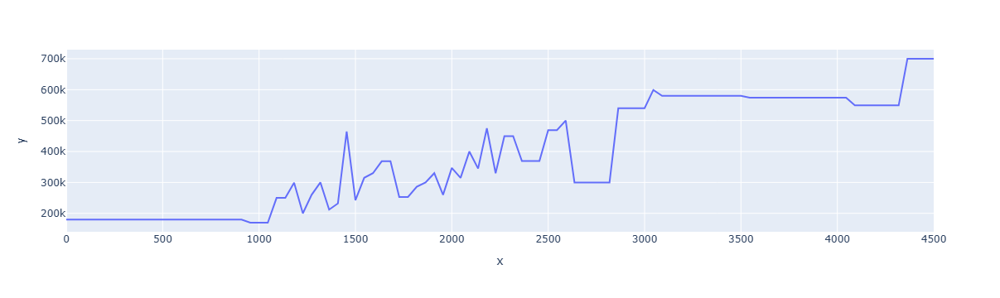

In [63]:
x_reg = np.linspace(0, 4500, 100)
y_reg = model_tree.predict(x_reg.reshape(100,1))
px.line(x=x_reg, y=y_reg)

In [64]:
model_tree.score(X, y)

1.0

### Wizualizacja drzew

In [65]:
from sklearn import tree

In [66]:
# forma tekstowa
print(tree.export_text(model_tree, feature_names=list(X.columns)))

|--- Size <= 2818.50
|   |--- Size <= 1992.50
|   |   |--- Size <= 1447.50
|   |   |   |--- Size <= 1050.00
|   |   |   |   |--- Size <= 926.00
|   |   |   |   |   |--- value: [179900.00]
|   |   |   |   |--- Size >  926.00
|   |   |   |   |   |--- value: [169900.00]
|   |   |   |--- Size >  1050.00
|   |   |   |   |--- Size <= 1201.50
|   |   |   |   |   |--- Size <= 1150.00
|   |   |   |   |   |   |--- value: [249900.00]
|   |   |   |   |   |--- Size >  1150.00
|   |   |   |   |   |   |--- value: [299000.00]
|   |   |   |   |--- Size >  1201.50
|   |   |   |   |   |--- Size <= 1350.00
|   |   |   |   |   |   |--- Size <= 1253.50
|   |   |   |   |   |   |   |--- Size <= 1219.50
|   |   |   |   |   |   |   |   |--- value: [239500.00]
|   |   |   |   |   |   |   |--- Size >  1219.50
|   |   |   |   |   |   |   |   |--- Size <= 1237.50
|   |   |   |   |   |   |   |   |   |--- value: [199900.00]
|   |   |   |   |   |   |   |   |--- Size >  1237.50
|   |   |   |   |   |   |   |   |   |--- 

In [67]:
# forma grafu
plt.figure(figsize=(20,16), dpi=800)
_ = tree.plot_tree(model_tree, feature_names=list(X.columns), filled=True)
plt.show()

## Drzewo z parametrami

In [68]:
model_tree_par = DecisionTreeRegressor(max_depth=3, min_samples_split=6)
model_tree_par.fit(X, y)

DecisionTreeRegressor(max_depth=3, min_samples_split=6)

In [69]:
model_tree_par.predict(predict_data)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning:

X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names



array([568340., 568340.])

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning:

X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names



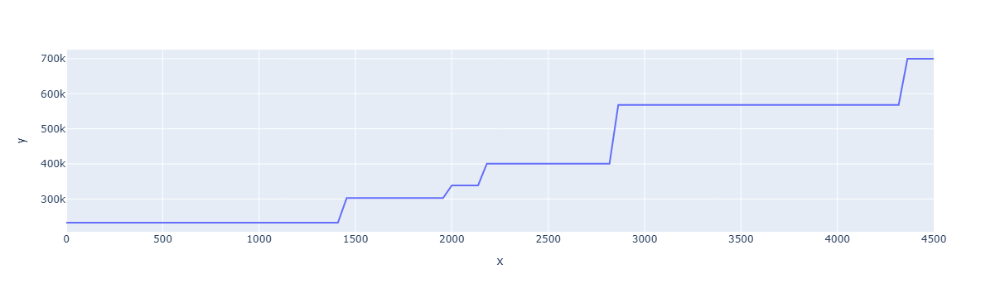

In [70]:
x_reg = np.linspace(0, 4500, 100)
y_reg = model_tree_par.predict(x_reg.reshape(100,1))
px.line(x=x_reg, y=y_reg)

In [71]:
model_tree.score(X, y)

1.0

In [72]:
model_tree_par.score(X, y)

0.8225885329271279

In [73]:
print(tree.export_text(model_tree_par, feature_names=list(X.columns)))

|--- Size <= 2818.50
|   |--- Size <= 1992.50
|   |   |--- Size <= 1447.50
|   |   |   |--- value: [232361.46]
|   |   |--- Size >  1447.50
|   |   |   |--- value: [302439.87]
|   |--- Size >  1992.50
|   |   |--- Size <= 2181.00
|   |   |   |--- value: [338760.00]
|   |   |--- Size >  2181.00
|   |   |   |--- value: [400837.25]
|--- Size >  2818.50
|   |--- Size <= 4346.50
|   |   |--- value: [568340.00]
|   |--- Size >  4346.50
|   |   |--- value: [699900.00]



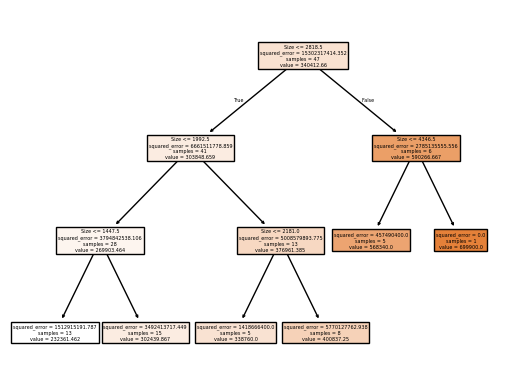

In [74]:
_ = tree.plot_tree(model_tree_par, feature_names=list(X.columns), filled=True)
plt.show()

In [70]:
# px.scatter(x=X.Size,y=y)

### Drzewa dla wielu cech

In [75]:
X = df[["Size", "Bedrooms"]]
y = df["Price"]

In [76]:
predict_data_2

array([[3200,    3],
       [3720,    2]])

In [77]:
model_tree_2_param = DecisionTreeRegressor(max_depth=4, min_samples_split=4)
model_tree_2_param.fit(X, y)
model_tree_2_param.predict(predict_data_2)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning:

X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names



array([584266.66666667, 584266.66666667])

In [78]:
model_tree_2_param.score(X, y)

0.8970352189500486

In [79]:
print(tree.export_text(model_tree_2_param, feature_names=list(X.columns)))

|--- Size <= 2818.50
|   |--- Size <= 1992.50
|   |   |--- Size <= 1447.50
|   |   |   |--- Size <= 1050.00
|   |   |   |   |--- value: [174900.00]
|   |   |   |--- Size >  1050.00
|   |   |   |   |--- value: [242809.00]
|   |   |--- Size >  1447.50
|   |   |   |--- Size <= 1476.00
|   |   |   |   |--- value: [464500.00]
|   |   |   |--- Size >  1476.00
|   |   |   |   |--- value: [290864.14]
|   |--- Size >  1992.50
|   |   |--- Size <= 2181.00
|   |   |   |--- Bedrooms <= 3.50
|   |   |   |   |--- value: [373450.00]
|   |   |   |--- Bedrooms >  3.50
|   |   |   |   |--- value: [315633.33]
|   |   |--- Size >  2181.00
|   |   |   |--- Size <= 2623.00
|   |   |   |   |--- value: [415256.86]
|   |   |   |--- Size >  2623.00
|   |   |   |   |--- value: [299900.00]
|--- Size >  2818.50
|   |--- Size <= 4346.50
|   |   |--- Size <= 3015.50
|   |   |   |--- value: [539900.00]
|   |   |--- Size >  3015.50
|   |   |   |--- Size <= 4052.50
|   |   |   |   |--- value: [584266.67]
|   |   |   |-

# Podział danych

In [80]:
from sklearn.model_selection import train_test_split

In [81]:
boston_df = pd.read_csv("ML-datasets/boston.csv")

In [82]:
X = boston_df.drop("target", axis=1)
y = boston_df.target

In [83]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [84]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(404, 14)
(102, 14)
(404,)
(102,)


In [85]:
model_boston_tree = DecisionTreeRegressor(max_depth=5, min_samples_split=10)
model_boston_tree.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=5, min_samples_split=10)

In [86]:
predicted = model_boston_tree.predict(X_test)

In [87]:
print(y_test.iloc[3], predicted[3])

22.8 20.355555555555554


# Metryki regresji

In [88]:
from sklearn.metrics import r2_score

In [89]:
r2_score(y_test, predicted)

0.7420407277318674

In [90]:
model_boston_tree.score(X_test, y_test)

0.7420407277318674

In [91]:
model_boston_tree.score(X_train, y_train)

0.9051955797925586

In [92]:
predicted_train = model_boston_tree.predict(X_train)
r2_score(y_train, predicted_train)

0.9051955797925586

In [93]:
from sklearn.metrics import mean_absolute_error #MAE
mean_absolute_error(y_test, predicted)

2.6737154149409057

In [94]:
from sklearn.metrics import mean_absolute_percentage_error #MAPE
mean_absolute_percentage_error(y_test, predicted)

0.15167326569450318

In [95]:
from sklearn.metrics import mean_squared_error #MSE
mean_squared_error(y_test, predicted)

18.91712933670595

In [96]:
from sklearn.metrics import root_mean_squared_error #RMSE
root_mean_squared_error(y_test, predicted)

4.349382638571359

# Kroswalidacja

In [97]:
from sklearn.model_selection import KFold

In [99]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

i = 1
results_list = []
for train, test in cv.split(X, y):
    # print("Iteracja", i)
    # print(train, test)
    X_train, y_train = X.iloc[train], y.iloc[train]
    X_test, y_test = X.iloc[test], y.iloc[test] 
    model_boston_tree = DecisionTreeRegressor(max_depth=5, min_samples_split=10, random_state=42)
    model_boston_tree.fit(X_train, y_train)
    result = model_boston_tree.score(X_test, y_test)
    results_list.append(result)
    i += 1

In [100]:
print(results_list)
print(np.mean(results_list))

[0.7420407277318672, 0.8256139927657801, 0.5842778822932966, 0.8151272552830275, 0.8227656053065705]
0.7579650926761083


In [101]:
# końcowo trenujemy model na całym zbiorze!
model_boston_tree_final = DecisionTreeRegressor(max_depth=4, min_samples_split=10, random_state=42)
model_boston_tree_final.fit(X, y)

DecisionTreeRegressor(max_depth=4, min_samples_split=10, random_state=42)

# Zapisywanie modelu

In [102]:
# pickle, pyarrow, joblib #parquet #avro

import pickle

In [103]:
# zapisywanie modelu
with open("model.pkl", "wb") as file:
    pickle.dump(model_boston_tree_final, file)

In [104]:
# wczytanie modelu
with open("model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

In [105]:
loaded_model.predict(X_test)

array([21.62974359, 21.62974359, 16.23896104, 21.62974359, 16.23896104,
       21.62974359, 20.02083333, 20.02083333, 21.62974359, 21.62974359,
       21.62974359, 20.02083333, 21.62974359, 21.62974359, 27.42727273,
       21.62974359, 32.74878049, 21.62974359, 32.74878049, 21.62974359,
       20.02083333, 20.02083333, 21.62974359, 21.62974359, 16.23896104,
       16.23896104, 21.62974359, 21.62974359, 48.3       , 48.3       ,
       21.62974359, 21.62974359, 27.42727273, 27.42727273, 32.74878049,
       32.74878049, 27.42727273, 21.62974359, 21.62974359, 20.02083333,
       27.42727273, 21.62974359, 21.62974359, 21.62974359, 21.62974359,
       32.74878049, 48.3       , 27.42727273, 32.74878049, 32.74878049,
       21.62974359, 21.62974359, 43.65333333, 32.74878049, 21.62974359,
       27.42727273, 32.74878049, 32.74878049, 27.42727273, 21.62974359,
       21.62974359, 21.62974359, 21.62974359, 21.62974359, 21.62974359,
       21.62974359, 27.42727273, 27.42727273, 21.62974359, 27.42

# Leave one out

In [106]:
from sklearn.model_selection import LeaveOneOut

cv = LeaveOneOut()

i = 1
results_list = []
for train, test in cv.split(X, y):
    # print("Iteracja", i)
    # print(train, test)
    X_train, y_train = X.iloc[train], y.iloc[train]
    X_test, y_test = X.iloc[test], y.iloc[test] 
    model_boston_tree = DecisionTreeRegressor(max_depth=4, min_samples_split=10, random_state=42)
    model_boston_tree.fit(X_train, y_train)
    predicted = model_boston_tree.predict(X_test)
    result = mean_absolute_error(y_test, predicted)
    results_list.append(result)
    i += 1

In [107]:
# print(results_list)
print(np.mean(results_list))

3.0692806134062294


# Klasyfikacja

In [108]:
# losowe dane dwuwymiarowe dla dwóch klas z przesuniętym środkiem rozkładu normalnego
train_data = np.vstack((np.random.normal(size=(100,2)), np.random.normal(size=(100,2), loc=2)))
train_labels = np.hstack((np.zeros(100), np.ones(100)))

In [109]:
train_labels

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

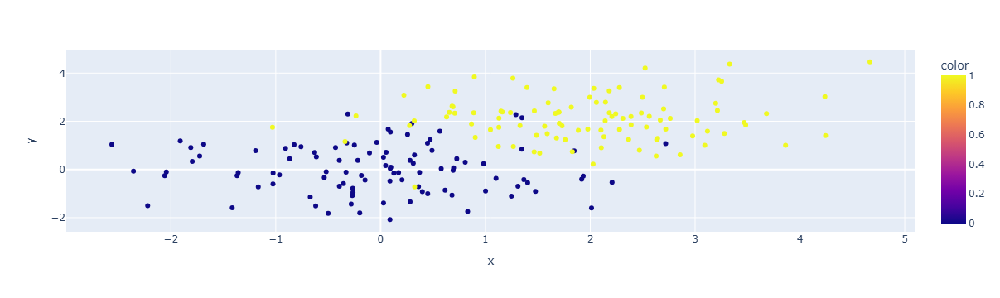

In [110]:
px.scatter(x=train_data[:,0], y=train_data[:,1], color=train_labels)

In [111]:
def get_grid(data):
    x_min, x_max = data[:,0].min() - 1, data[:,0].max() + 1
    y_min, y_max = data[:,1].min() - 1, data[:,1].max() + 1
    return np.meshgrid(np.arange(x_min, x_max, 0.01), np.arange(y_min, y_max, 0.01))

In [107]:
# get_grid(train_data)

## Regresja logistyczna

In [112]:
from sklearn.linear_model import LogisticRegression

In [114]:
model_log = LogisticRegression()
model_log.fit(train_data, train_labels)

LogisticRegression()

In [115]:
xs, ys = get_grid(train_data)
predicted = model_log.predict(np.column_stack((xs.flatten(), ys.flatten()))).reshape(xs.shape)

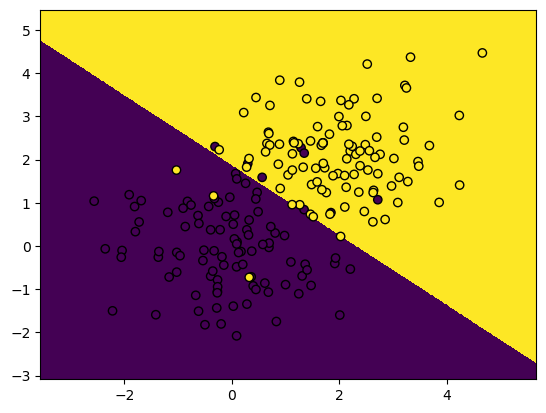

In [116]:
fig, ax = plt.subplots()
ax.pcolormesh(xs, ys, predicted)
ax.scatter(x=train_data[:,0], y=train_data[:,1], c=train_labels, edgecolors="k")
plt.show()

In [117]:
diabetes = pd.read_csv("ML-datasets/diabetes.csv")
diabetes.head()

,Number of times pregnant,Plasma glucose concentration,Diastolic blood pressure,Triceps skin fold thickness,2-Hour serum insulin,Body mass index,Diabetes pedigree function,Age,Class
0,6,148,72,35,0,33.6,0.627,50,positive
1,1,85,66,29,0,26.6,0.351,31,negative
2,8,183,64,0,0,23.3,0.672,32,positive
3,1,89,66,23,94,28.1,0.167,21,negative
4,0,137,40,35,168,43.1,2.288,33,positive


In [118]:
X = diabetes.drop("Class", axis=1)
# y = diabetes.Class.astype("category")
y = diabetes.Class.astype("category").cat.codes # do metryk

In [119]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [121]:
model_log_1 = LogisticRegression(max_iter=200)
model_log_1.fit(X_train, y_train)

LogisticRegression(max_iter=200)

In [122]:
model_log_1.score(X_test, y_test)

0.7467532467532467

In [123]:
model_log_1.coef_

array([[ 0.06436734,  0.0340962 , -0.01387857,  0.00329218, -0.00180357,
         0.10260186,  0.62672468,  0.03709603]])

In [124]:
model_log_1.predict(X_test)

array([0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1,
       0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
      dtype=int8)

In [125]:
# prawdopodobieństwa
model_log_1.predict_proba(X_test)

array([[0.72413787, 0.27586213],
       [0.81155998, 0.18844002],
       [0.88551552, 0.11448448],
       [0.83645838, 0.16354162],
       [0.52847171, 0.47152829],
       [0.55819635, 0.44180365],
       [0.98454073, 0.01545927],
       [0.33922992, 0.66077008],
       [0.45852752, 0.54147248],
       [0.22266595, 0.77733405],
       [0.74408346, 0.25591654],
       [0.10265098, 0.89734902],
       [0.66379796, 0.33620204],
       [0.69697385, 0.30302615],
       [0.91801998, 0.08198002],
       [0.6190713 , 0.3809287 ],
       [0.86065176, 0.13934824],
       [0.92520744, 0.07479256],
       [0.13325429, 0.86674571],
       [0.43857363, 0.56142637],
       [0.79159121, 0.20840879],
       [0.92260633, 0.07739367],
       [0.460384  , 0.539616  ],
       [0.90541794, 0.09458206],
       [0.46051007, 0.53948993],
       [0.11444685, 0.88555315],
       [0.87568566, 0.12431434],
       [0.96983608, 0.03016392],
       [0.74848252, 0.25151748],
       [0.88418895, 0.11581105],
       [0.

In [126]:
# zmiana progu klasyfikacji
predicted_proba = model_log_1.predict_proba(X_test)
predicted_list = []
for result in predicted_proba:
    if result[1] > 0.1:
        predicted_list.append(1)
    else:
        predicted_list.append(0)
print(predicted_list)

[1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1]


## Metryki klasyfikacji

In [127]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [128]:
predicted = model_log_1.predict(X_test)

In [129]:
cm = confusion_matrix(y_test, predicted)

In [130]:
cm

array([[78, 21],
       [18, 37]], dtype=int64)

In [131]:
accuracy = accuracy_score(y_test, predicted)
precision = precision_score(y_test, predicted)
recall = recall_score(y_test, predicted)
f1score = f1_score(y_test, predicted)
auc = roc_auc_score(y_test, predicted)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1score: {f1score}")
print(f"ROC-AUC: {auc}")

Accuracy: 0.7467532467532467
Precision: 0.6379310344827587
Recall: 0.6727272727272727
F1score: 0.6548672566371682
ROC-AUC: 0.7303030303030302


In [132]:
# zbiór treningowy
predicted_train = model_log_1.predict(X_train)

accuracy = accuracy_score(y_train, predicted_train)
precision = precision_score(y_train, predicted_train)
recall = recall_score(y_train, predicted_train)
f1score = f1_score(y_train, predicted_train)
auc = roc_auc_score(y_train, predicted_train)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1score: {f1score}")
print(f"ROC-AUC: {auc}")

Accuracy: 0.7703583061889251
Precision: 0.7142857142857143
Recall: 0.5633802816901409
F1score: 0.6299212598425197
ROC-AUC: 0.7218397667802325


In [133]:
# obniżony próg
accuracy = accuracy_score(y_test, predicted_list)
precision = precision_score(y_test, predicted_list)
recall = recall_score(y_test, predicted_list)
f1score = f1_score(y_test, predicted_list)
auc = roc_auc_score(y_test, predicted_list)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1score: {f1score}")
print(f"ROC-AUC: {auc}")

Accuracy: 0.564935064935065
Precision: 0.45
Recall: 0.9818181818181818
F1score: 0.6171428571428571
ROC-AUC: 0.6575757575757577


## GridSearch

In [134]:
from sklearn.model_selection import GridSearchCV

In [135]:
model_research = LogisticRegression(max_iter=1000)

parameters_dict = {"C": [0.001, 0.01, 0.1, 1, 10], "solver": ["lbfgs", "liblinear", "newton-cg", "newton-cholesky", "sag", "saga"]}

search = GridSearchCV(model_research, parameters_dict, scoring="f1", n_jobs=6, verbose=1)
search.fit(X, y)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


GridSearchCV(estimator=LogisticRegression(max_iter=1000), n_jobs=6,
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10],
                         'solver': ['lbfgs', 'liblinear', 'newton-cg',
                                    'newton-cholesky', 'sag', 'saga']},
             scoring='f1', verbose=1)

In [136]:
# najlepsze parametry
print(search.best_params_)
# najlepszy model
print(search.best_estimator_)
# najlepszy score
print(search.best_score_)

{'C': 1, 'solver': 'lbfgs'}
LogisticRegression(C=1, max_iter=1000)
0.6374328442978329


In [137]:
search.best_estimator_.predict(X_test)

array([0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1,
       0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
      dtype=int8)

## Drzewa decyzyjne

In [138]:
from sklearn.tree import DecisionTreeClassifier

In [145]:
model_tree = DecisionTreeClassifier(max_depth=3)
model_tree.fit(train_data, train_labels)

DecisionTreeClassifier(max_depth=3)

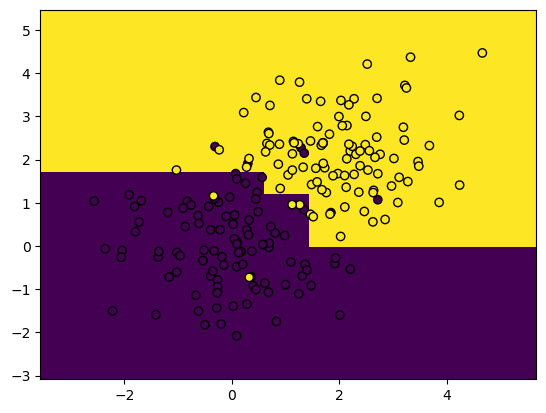

In [146]:
xs, ys = get_grid(train_data)
predicted = model_tree.predict(np.column_stack((xs.flatten(), ys.flatten()))).reshape(xs.shape)

fig, ax = plt.subplots()
ax.pcolormesh(xs, ys, predicted)
ax.scatter(x=train_data[:,0], y=train_data[:,1], c=train_labels, edgecolors="k")
plt.show()

In [147]:
print(tree.export_text(model_tree))

|--- feature_1 <= 1.21
|   |--- feature_0 <= 1.43
|   |   |--- feature_1 <= 0.95
|   |   |   |--- class: 0.0
|   |   |--- feature_1 >  0.95
|   |   |   |--- class: 0.0
|   |--- feature_0 >  1.43
|   |   |--- feature_1 <= -0.03
|   |   |   |--- class: 0.0
|   |   |--- feature_1 >  -0.03
|   |   |   |--- class: 1.0
|--- feature_1 >  1.21
|   |--- feature_0 <= 0.60
|   |   |--- feature_1 <= 1.72
|   |   |   |--- class: 0.0
|   |   |--- feature_1 >  1.72
|   |   |   |--- class: 1.0
|   |--- feature_0 >  0.60
|   |   |--- feature_0 <= 1.37
|   |   |   |--- class: 1.0
|   |   |--- feature_0 >  1.37
|   |   |   |--- class: 1.0



In [148]:
# diabetes
X = diabetes.drop("Class", axis=1)
y = diabetes.Class.astype("category").cat.codes

In [149]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [150]:
model_tree_d = DecisionTreeClassifier(max_depth=5)
model_tree_d.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5)

In [151]:
predicted = model_tree_d.predict(X_test)

In [152]:
accuracy = accuracy_score(y_test, predicted)
precision = precision_score(y_test, predicted, average="macro")
recall = recall_score(y_test, predicted, average="macro")
f1score = f1_score(y_test, predicted, average="macro")

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1score: {f1score}")

Accuracy: 0.7922077922077922
Precision: 0.7788824816066813
Recall: 0.7575757575757576
F1score: 0.7654673519893394


In [153]:
#gridsearch
from sklearn.model_selection import GridSearchCV

model_tree_search = DecisionTreeClassifier()

parameters = {"max_depth": [2,3,4,5,6,7,8], "min_samples_split": [2,3,4,5,6,7,8,9,10], "min_samples_leaf": [1,2,3,4], "criterion": ["gini", "entropy", "log_loss"]}

searcher = GridSearchCV(model_tree_search, parameters, scoring="f1", n_jobs=6)
searcher.fit(X_train, y_train)

GridSearchCV(estimator=DecisionTreeClassifier(), n_jobs=6,
             param_grid={'criterion': ['gini', 'entropy', 'log_loss'],
                         'max_depth': [2, 3, 4, 5, 6, 7, 8],
                         'min_samples_leaf': [1, 2, 3, 4],
                         'min_samples_split': [2, 3, 4, 5, 6, 7, 8, 9, 10]},
             scoring='f1')

In [154]:
# najlepsze parametry
print(searcher.best_params_)
# najlepszy model
print(searcher.best_estimator_)
# najlepszy score
print(searcher.best_score_)

{'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 2, 'min_samples_split': 2}
DecisionTreeClassifier(max_depth=4, min_samples_leaf=2)
0.6862047261265669


# Zespoły klasyfikatorów

## Random Forest

In [155]:
from sklearn.ensemble import RandomForestClassifier

In [156]:
forest = RandomForestClassifier()
forest.fit(train_data, train_labels)

RandomForestClassifier()

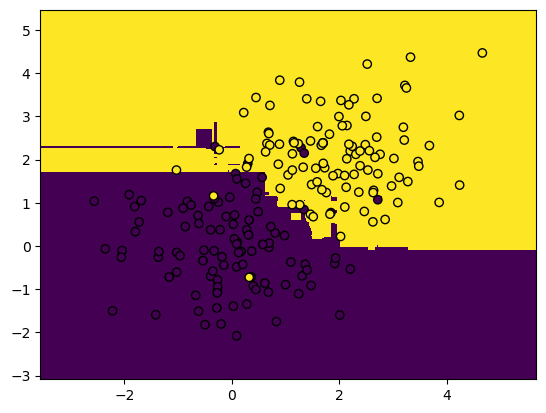

In [158]:
xs, ys = get_grid(train_data)
predicted = forest.predict(np.column_stack((xs.flatten(), ys.flatten()))).reshape(xs.shape)

fig, ax = plt.subplots()
ax.pcolormesh(xs, ys, predicted)
ax.scatter(x=train_data[:,0], y=train_data[:,1], c=train_labels, edgecolors="k")
plt.show()

In [159]:
# diabetes
forest_diabetes = RandomForestClassifier(max_depth=3)
forest_diabetes.fit(X_train, y_train)

RandomForestClassifier(max_depth=3)

In [160]:
predicted = forest_diabetes.predict(X_test)

In [161]:
accuracy = accuracy_score(y_test, predicted)
precision = precision_score(y_test, predicted, average="macro")
recall = recall_score(y_test, predicted, average="macro")
f1score = f1_score(y_test, predicted, average="macro")

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1score: {f1score}")

Accuracy: 0.7922077922077922
Precision: 0.7884739909345997
Recall: 0.7454545454545454
F1score: 0.7578616352201257


In [162]:
# grid search forest
# parametry -> liczba estymatorów, max_samples, max_depth, min_samples_split

model_forest_search = RandomForestClassifier()

parameters = {"n_estimators": [50,70,80,90,100,120,150], "max_samples": [0.4, 0.6, 0.8, 1],"max_depth": [2,3,4,5,6,7,8], "min_samples_split": [2,3,4,5,6,7,8,9,10]}

searcher = GridSearchCV(model_forest_search, parameters, scoring="f1", n_jobs=6)
searcher.fit(X, y)

C:\ProgramData\anaconda3\Lib\site-packages\numpy\ma\core.py:2820: RuntimeWarning:

invalid value encountered in cast



GridSearchCV(estimator=RandomForestClassifier(), n_jobs=6,
             param_grid={'max_depth': [2, 3, 4, 5, 6, 7, 8],
                         'max_samples': [0.4, 0.6, 0.8, 1],
                         'min_samples_split': [2, 3, 4, 5, 6, 7, 8, 9, 10],
                         'n_estimators': [50, 70, 80, 90, 100, 120, 150]},
             scoring='f1')

In [163]:
# najlepsze parametry
print(searcher.best_params_)
# najlepszy model
print(searcher.best_estimator_)
# najlepszy score
print(searcher.best_score_)

{'max_depth': 8, 'max_samples': 0.6, 'min_samples_split': 8, 'n_estimators': 120}
RandomForestClassifier(max_depth=8, max_samples=0.6, min_samples_split=8,
                       n_estimators=120)
0.6598527201590679


## XGBoost

In [164]:
!pip install -U xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   -------------------------------------- - 46.7/48.9 MB 228.6 MB/s eta 0:00:01
   ---------------------------------------  48.8/48.9 MB 222.5 MB/s eta 0:00:01
   ---------------------------------------  48.8/48.9 MB 222.5 MB/s eta 0:00:01
   ---------------------------------------  48.8/48.9 MB 222.5 MB/s eta 0:00:01
   ---------------------------------------- 48.9/48.9 MB 52.0 MB/s eta 0:00:00


In [165]:
from xgboost import XGBClassifier

In [166]:
xgb_model = XGBClassifier()
xgb_model.fit(train_data, train_labels)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

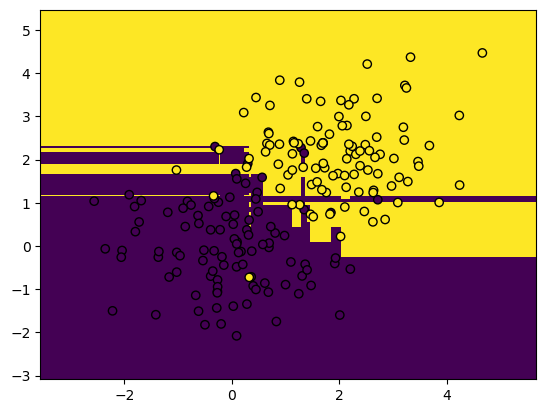

In [167]:
xs, ys = get_grid(train_data)
predicted = xgb_model.predict(np.column_stack((xs.flatten(), ys.flatten()))).reshape(xs.shape)

fig, ax = plt.subplots()
ax.pcolormesh(xs, ys, predicted)
ax.scatter(x=train_data[:,0], y=train_data[:,1], c=train_labels, edgecolors="k")
plt.show()

In [178]:
# diabetes
xgb_d = XGBClassifier()
xgb_d.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [179]:
predicted = xgb_d.predict(X_test)

In [180]:
accuracy = accuracy_score(y_test, predicted)
precision = precision_score(y_test, predicted, average="macro")
recall = recall_score(y_test, predicted, average="macro")
f1score = f1_score(y_test, predicted, average="macro")

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1score: {f1score}")

Accuracy: 0.6948051948051948
Precision: 0.678030303030303
Recall: 0.6898989898989899
F1score: 0.6801166747690812


In [158]:
# grid search
# min_child_weight 1-10, max_depth 3-7, gamma 0.001-10, subsample 0.5-1, colsample_bytree 0.5-1 po 3

In [ ]:
params = {
        'min_child_weight': [1, 5, 10],
        'gamma': [0.5, 1, 1.5, 2, 5],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
        'max_depth': [3, 4, 5]
        }

xgb = XGBClassifier(n_estimators=500, learning_rate=0.1, objective="binary:logistic", n_jobs=-1)

searcher = GridSearchCV(xgb, params, cv=5, scoring="f1", n_jobs=-1, verbose=3)
searcher.fit(X_train, y_train)

Fitting 5 folds for each of 405 candidates, totalling 2025 fits


In [ ]:
# najlepsze parametry
print(searcher.best_params_)
# najlepszy model
print(searcher.best_estimator_)
# najlepszy score
print(searcher.best_score_)